In [1]:
import pandas as pd
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor

df = pd.read_csv('housing.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB


In [2]:
df = pd.get_dummies(df, columns=['ocean_proximity'])

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   longitude                   20640 non-null  float64
 1   latitude                    20640 non-null  float64
 2   housing_median_age          20640 non-null  float64
 3   total_rooms                 20640 non-null  float64
 4   total_bedrooms              20433 non-null  float64
 5   population                  20640 non-null  float64
 6   households                  20640 non-null  float64
 7   median_income               20640 non-null  float64
 8   median_house_value          20640 non-null  float64
 9   ocean_proximity_<1H OCEAN   20640 non-null  bool   
 10  ocean_proximity_INLAND      20640 non-null  bool   
 11  ocean_proximity_ISLAND      20640 non-null  bool   
 12  ocean_proximity_NEAR BAY    20640 non-null  bool   
 13  ocean_proximity_NEAR OCEAN  20640 non-null

In [4]:
df.isna().sum()

longitude                       0
latitude                        0
housing_median_age              0
total_rooms                     0
total_bedrooms                207
population                      0
households                      0
median_income                   0
median_house_value              0
ocean_proximity_<1H OCEAN       0
ocean_proximity_INLAND          0
ocean_proximity_ISLAND          0
ocean_proximity_NEAR BAY        0
ocean_proximity_NEAR OCEAN      0
dtype: int64

In [5]:
df = df.dropna(subset=['total_bedrooms'])

In [6]:
X = df.drop(columns=['median_house_value'])
y = df['median_house_value']

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
kn_reg = KNeighborsRegressor(n_neighbors=10)
kn_reg.fit(X_train_scaled, y_train)
y_pred = kn_reg.predict(X_test_scaled)

rmse = root_mean_squared_error(y_test, y_pred)
print(f"RMSE: {rmse}")

RMSE: 60735.75821758203


In [10]:
kn_reg_non_scaled = KNeighborsRegressor(n_neighbors=5)
kn_reg_non_scaled.fit(X_train, y_train)
y_pred = kn_reg_non_scaled.predict(X_test)

rmse = root_mean_squared_error(y_test, y_pred)
print(f"RMSE: {rmse}")

RMSE: 99127.24213107704


In [11]:
import numpy as np 
from sklearn.model_selection import cross_val_score

k_values = [1, 3, 5, 10, 20, 50, 100]
train_errors = []
cv_errors = []

for k in k_values:
    kn_model = KNeighborsRegressor(n_neighbors=k)
    kn_model.fit(X_train_scaled, y_train)
    
    train_pred = kn_model.predict(X_train_scaled)
    train_rmse = root_mean_squared_error(y_train, train_pred)
    
    # Cross-validation sul solo training, il segno va rimesso
    cv_rmse = -cross_val_score(kn_model, X_train_scaled, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
    
    train_errors.append(train_rmse)
    cv_errors.append(cv_rmse)

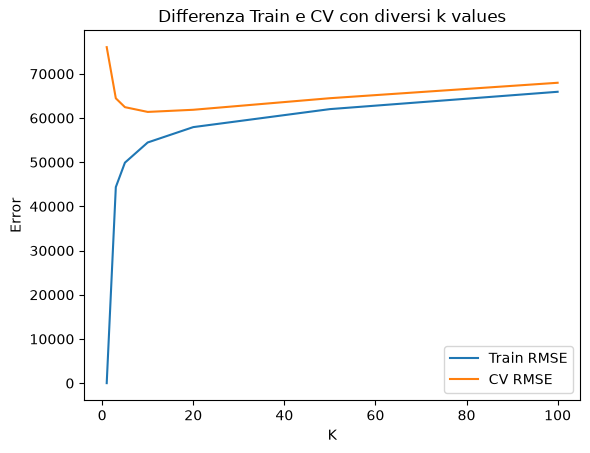

In [12]:
from matplotlib import pyplot as plt

plt.plot(k_values, train_errors, label='Train RMSE')
plt.plot(k_values, cv_errors, label='CV RMSE')
plt.xlabel('K')
plt.ylabel('Error')
plt.legend()
plt.title('Differenza Train e CV con diversi k values')
plt.show()

In [13]:
k_best_idx = np.argmin(cv_errors)
print(f'K ottimale: {k_values[k_best_idx]}, RMSE: {cv_errors[k_best_idx]}')

# Valutazione sul test, una volta sola
kn_best = KNeighborsRegressor(n_neighbors=k_values[k_best_idx])
kn_best.fit(X_train_scaled, y_train)
y_pred = kn_best.predict(X_test_scaled)

rmse = root_mean_squared_error(y_test, y_pred)
print(f"RMSE: {rmse}")

K ottimale: 10, RMSE: 61383.53993582474


RMSE: 60735.75821758203


In [14]:
casa_1 = X_test_scaled[34:35]
casa_1_prezzo = y_test[34]
print(casa_1_prezzo)
print(casa_1)
casa_1_pred = kn_reg.predict(X_test_scaled[34:35])
print(casa_1_pred)

109700.0
[[ 1.1854097  -1.32673543 -0.12756257 -0.60427154 -0.76187575 -0.8101955
  -0.80676654  0.73828835 -0.89646918 -0.67500217 -0.01182583 -0.35702009
   2.60745095]]
[227560.1]


In [15]:
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression

n_features_list = [5, 20, 50, 100]
knn_errors = []
reg_errors = []
scaler = StandardScaler()
for features in n_features_list:
     X_synth, y_synth = make_regression(n_samples=1000, n_informative=5, n_features=features, noise=10, random_state=42)
     
     X_synth_train, X_synth_test, y_synth_train, y_synth_test = train_test_split(X_synth, y_synth, test_size=0.3, random_state=42)
     
     X_synth_train_scaled = scaler.fit_transform(X_synth_train)
     X_synth_test_scaled = scaler.transform(X_synth_test)
     
     knn_synth = KNeighborsRegressor(n_neighbors=10)
     linear_reg = LinearRegression()
     
     knn_synth.fit(X_synth_train_scaled, y_synth_train)
     linear_reg.fit(X_synth_train_scaled, y_synth_train)
     
     y_pred_kn = knn_synth.predict(X_synth_test_scaled)
     y_pred_reg =linear_reg.predict(X_synth_test_scaled)
     
     rmse_knn = root_mean_squared_error(y_synth_test, y_pred_kn)
     rmse_reg = root_mean_squared_error(y_synth_test, y_pred_reg)
     
     knn_errors.append(rmse_knn)
     reg_errors.append(rmse_reg)

In [16]:
print(f'Errori KNN: {knn_errors}')
print(f'Errori regressione lineare: {reg_errors}')

Errori KNN: [22.250852745633637, 101.51170567266507, 104.92845118846257, 89.93647686440785]
Errori regressione lineare: [10.534939377195563, 9.99338057934206, 10.689704680736195, 11.078224757824609]


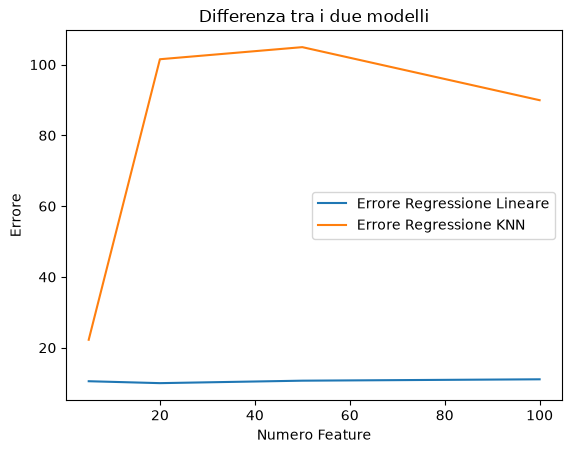

In [17]:
plt.plot(n_features_list, reg_errors, label='Errore Regressione Lineare')
plt.plot(n_features_list, knn_errors, label='Errore Regressione KNN')
plt.xlabel('Numero Feature')
plt.ylabel('Errore')
plt.legend()
plt.title('Differenza tra i due modelli')
plt.show()